## 📦 Step 1 — Import Libraries & Load Dataset

**What we do here:**
- Import all the Python libraries we need (pandas, sklearn, matplotlib, etc.)
- Load the phishing URL dataset from `project.csv`

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('project.csv')

In [3]:
df.shape

(235795, 56)

In [4]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


---
## 🔍 Step 2 — Check & Clean Data

**What we do here:**
- Check for missing values and duplicate rows
- Look at the class distribution (legitimate vs phishing)
- Identify which columns are text/object type
- Drop columns we don't need: `FILENAME`, `URL`, `Domain`, `Title`


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

In [6]:
df.isnull().sum().sum()

np.int64(0)

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['label'].value_counts()

label
1    134850
0    100945
Name: count, dtype: int64

In [9]:
df.select_dtypes(include='object').columns
# got 5 object

Index(['FILENAME', 'URL', 'Domain', 'TLD', 'Title'], dtype='object')

In [10]:
df_clean = df.drop(columns=['FILENAME', 'URL', 'Domain', 'Title'])
df_clean.shape

(235795, 52)

In [11]:
df['URL'].nunique()

235370

In [12]:
df['Domain'].nunique()

220086

In [13]:
df['Title'].nunique()

197874

In [14]:
df['TLD'].nunique()

695

---
## 🏷️ Step 3 — Encode TLD (Text → Number)

**What we do here:**
- TLD (Top-Level Domain) like `.com`, `.net`, `.org` is text — ML models need numbers
- We use `LabelEncoder` to convert each unique TLD into an integer
- Same TLD always gets the same number


In [15]:
le = LabelEncoder()

In [16]:
df['TLD_encoded'] = le.fit_transform(df['TLD'])

In [17]:
df[['TLD','TLD_encoded']].head(10)
# Same code name = same number

,TLD,TLD_encoded
0,com,231
1,de,254
2,uk,647
3,com,231
4,org,503
5,org,503
6,com,231
7,com,231
8,in,368
9,org,503


In [18]:
df_clean = df_clean.drop(columns=['TLD'])
df_clean.shape

(235795, 51)

---
## 🔧 Step 4 — Prepare Features (X) and Labels (y)

**What we do here:**
- Add `TLD_encoded` into our clean dataframe
- `X` = 51 feature columns (inputs to the model)
- `y` = `label` column (1 = Legitimate, 0 = Phishing)

**⚠️ Important:** `TLD_encoded` must be the **LAST** column in X — the saved scaler depends on this exact order.



In [19]:
df_clean['TLD_encoded'] = df['TLD_encoded']
df = df_clean.copy()

print(df.columns.tolist())

['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label', 'TLD_encoded']


In [20]:
# before drop label is 52

X = df.drop(columns=['label'])
y = df['label']
# after is 51
# A row that only displays a label.
print("X shape:", X.shape)
print("y shape", y.shape)

X shape: (235795, 51)
y shape (235795,)


---
## ✂️ Step 5 — Train/Test Split & Feature Scaling

**What we do here:**
- Split data: 80% training, 20% testing (`stratify=y` keeps class balance in both sets)
- `StandardScaler` normalises all features to mean=0, std=1 so no single feature dominates

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

# stratify=y （Ensure that the training set and the test set have the same number of samples.）

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (188636, 51)
X_test shape: (47159, 51)
y_train shape: (188636,)
y_test shape: (47159,)


In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Done scaling")
print(X_train_scaled[:2])

Done scaling
[[-0.2582902  -0.48816772 -0.05287945  0.74445584  0.71408399  1.04458853
   0.61394113  0.39167177 -0.27544102 -0.04522324 -0.01283941 -0.03592044
  -0.30284789 -0.4687109  -0.1502932  -0.40442994 -0.06329513 -0.15228304
  -0.02886874 -0.36535123 -0.65941076  0.52699844  0.01628539 -0.05668231
   0.4015167   1.00475223  0.96647456  1.32776742 -0.60317853  0.77482883
  -0.39283965 -0.20346893  1.12791966 -0.05581924 -0.26949991 -0.21480507
   1.0914676   1.18748865  1.28403645 -0.33760122 -0.38134147 -0.55809124
  -0.15484475  1.02575621  0.14537643  0.17510447  0.57329527  0.54386186
  -0.07533932 -0.14896875 -0.61281228]
 [-0.30709745 -0.70633344 -0.05287945  0.74445584 -0.43902575 -0.94206582
   1.08837153 -1.27293105  1.38620764 -0.04522324 -0.01283941 -0.03592044
  -0.41074082 -1.23110344 -0.1502932  -0.40442994 -0.06329513 -0.15228304
  -0.02886874 -0.09389713  0.85382815  0.52699844  0.21173693 -0.06345621
   0.4015167  -1.00837914 -1.04964484  1.32776742 -0.6031785

---
## 🌲 Step 6 — Random Forest Classifier

**What we do here:**
- Train a Random Forest with 100 decision trees
- Predict on test data and measure accuracy, precision, recall
- Check feature importance (which feature matters most?)
- Test again **without** the top feature (`URLSimilarityIndex`) to confirm the model doesn't cheat


In [23]:
# Building the Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model (using scaled training data)
rf_model.fit(X_train_scaled, y_train)

print("Training done!")

Training done!


In [24]:
# Predict using test data

# Work out the answers yourself for the questions you haven't looked at yet.
y_pred = rf_model.predict(X_test_scaled)

# Print the 4 metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [25]:
# Get feature importance from the trained model
importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
})

# Sort by importance, highest first
importance = importance.sort_values('importance', ascending=False)

print(importance.head(10))

               feature  importance
3   URLSimilarityIndex    0.190299
49     NoOfExternalRef    0.127629
47         NoOfSelfRef    0.108896
46              NoOfJS    0.108858
22          LineOfCode    0.102539
44           NoOfImage    0.083501
45             NoOfCSS    0.051608
36        HasSocialNet    0.050915
43    HasCopyrightInfo    0.034942
32      HasDescription    0.025167


In [26]:
# Try training WITHOUT the most dominant feature
X_test_v2 = X.drop(columns=['URLSimilarityIndex'])

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_test_v2, y, test_size=0.2, random_state=42, stratify=y
)

scaler2 = StandardScaler()
X_train2_scaled = scaler2.fit_transform(X_train2)
X_test2_scaled = scaler2.transform(X_test2)

rf_model2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model2.fit(X_train2_scaled, y_train2)

y_pred2 = rf_model2.predict(X_test2_scaled)

print("Accuracy without URLSimilarityIndex:", accuracy_score(y_test2, y_pred2))

Accuracy without URLSimilarityIndex: 0.9998939756992302


In [27]:
# We tested removing the most dominant feature (URLSimilarityIndex) 
# and retrained the model. Accuracy remained at 99.99%, confirming that the 
# near-perfect performance is not due to a single leaking feature, but rather 
# the highly engineered nature of this dataset's features (as also observed 
# in published research using this dataset). 

---
## 📊 Step 7 — Exploratory Data Analysis (EDA)


**What we do here:**
- Bar chart: count of legitimate vs phishing URLs
- Histograms: distribution of key URL length features (using 95th percentile to cut outliers)
- Heatmap: correlation between the top features



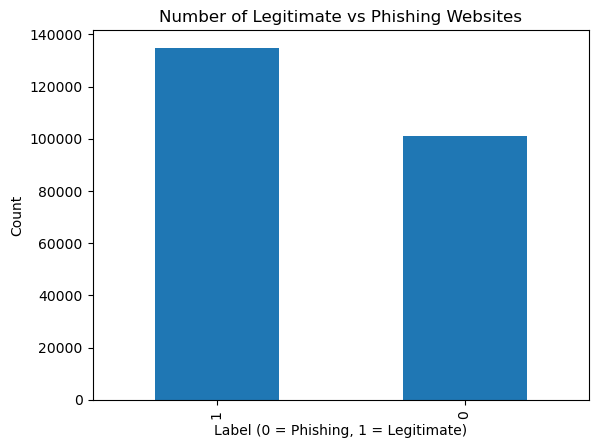

In [28]:
df['label'].value_counts().plot(kind='bar')
plt.title('Number of Legitimate vs Phishing Websites')
plt.xlabel('Label (0 = Phishing, 1 = Legitimate)')
plt.ylabel('Count')
plt.show()

In [29]:
# Use percentile to filter out extreme outliers just for visualization
for col in ['URLLength', 'LineOfCode', 'NoOfImage', 'NoOfJS']:
    upper_limit = df[col].quantile(0.95)  # look at the bottom 95% of data
    print(col, "95th percentile value:", upper_limit)

URLLength 95th percentile value: 73.0
LineOfCode 95th percentile value: 4391.0
NoOfImage 95th percentile value: 96.0
NoOfJS 95th percentile value: 38.0


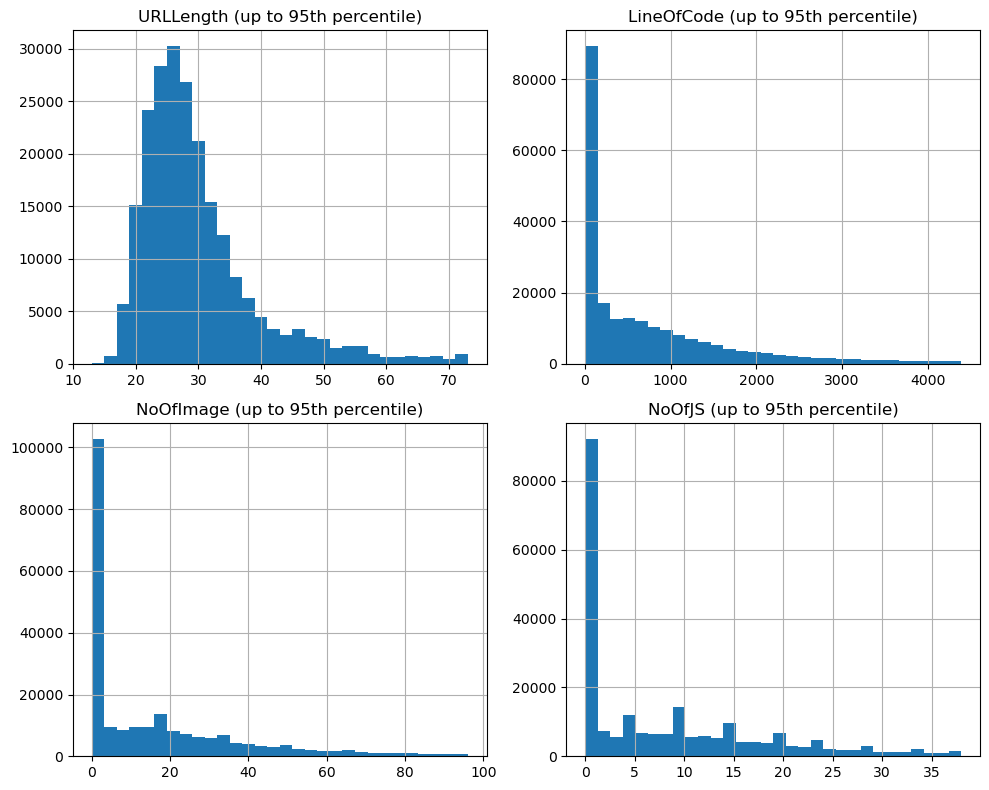

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

df[df['URLLength'] <= 73]['URLLength'].hist(bins=30, ax=axes[0, 0])
axes[0, 0].set_title('URLLength (up to 95th percentile)')

df[df['LineOfCode'] <= 4391]['LineOfCode'].hist(bins=30, ax=axes[0, 1])
axes[0, 1].set_title('LineOfCode (up to 95th percentile)')

df[df['NoOfImage'] <= 96]['NoOfImage'].hist(bins=30, ax=axes[1, 0])
axes[1, 0].set_title('NoOfImage (up to 95th percentile)')

df[df['NoOfJS'] <= 38]['NoOfJS'].hist(bins=30, ax=axes[1, 1])
axes[1, 1].set_title('NoOfJS (up to 95th percentile)')

plt.tight_layout()
plt.show()

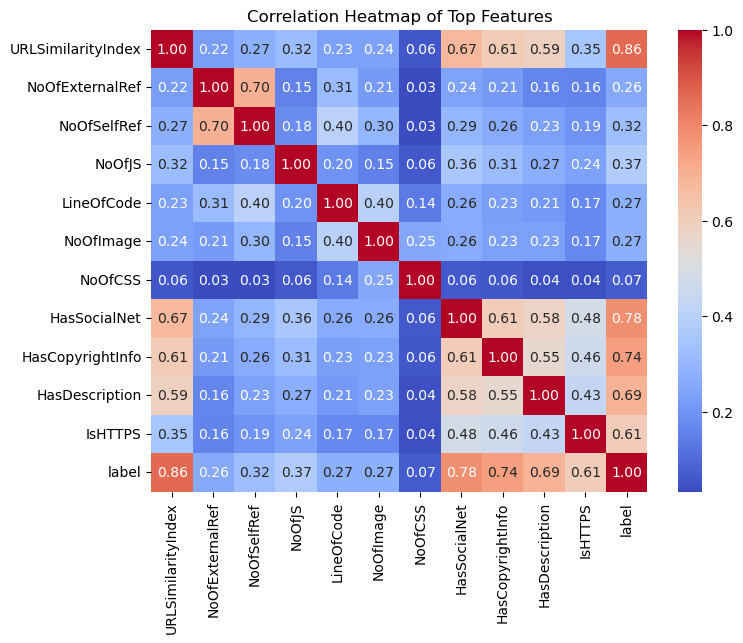

In [31]:
import seaborn as sns

top_features = ['URLSimilarityIndex', 'NoOfExternalRef', 'NoOfSelfRef', 'NoOfJS',
                'LineOfCode', 'NoOfImage', 'NoOfCSS', 'HasSocialNet',
                'HasCopyrightInfo', 'HasDescription', 'IsHTTPS', 'label']

correlation_matrix = df[top_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Top Features')
plt.show()

---
## 🌿 Step 8 — Decision Tree Classifier


**What we do here:**
- Train a single Decision Tree (simpler than Random Forest — one tree instead of 100)
- Compare Decision Tree vs Random Forest results side by side



In [32]:
from sklearn.tree import DecisionTreeClassifier

# Build the model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train_scaled, y_train)

print("Training done!")

Training done!


In [33]:
# Predict using test data
y_pred_dt = dt_model.predict(X_test_scaled)

# Print the 4 metrics
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [34]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'Decision Tree'],
    'Accuracy': [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_dt)],
    'Precision': [precision_score(y_test, y_pred), precision_score(y_test, y_pred_dt)],
    'Recall': [recall_score(y_test, y_pred), recall_score(y_test, y_pred_dt)],
    'F1 Score': [f1_score(y_test, y_pred), f1_score(y_test, y_pred_dt)]
})

print(comparison)

           Model  Accuracy  Precision  Recall  F1 Score
0  Random Forest       1.0        1.0     1.0       1.0
1  Decision Tree       1.0        1.0     1.0       1.0


---
## 🧠 Step 9 — ANN (Artificial Neural Network) — Build & Train

**What we do here:**
- Build a 3-layer neural network: Input → Dense(64, relu) → Dense(32, relu) → Dense(1, sigmoid)
- Compile with `adam` optimiser and `binary_crossentropy` loss
- Train for 20 epochs, track accuracy and loss on both train and validation sets
- Plot training curves to check for overfitting



In [35]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [36]:
model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(51,)),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.summary()

C:\Users\CHIN KANG JIE\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,441 (21.25 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled!")

Model compiled!


In [38]:
history = model.fit(
    X_train_scaled, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/20
4716/4716 ━━━━━━━━━━━━━━━━━━━━ 32s 6ms/step - accuracy: 0.9983 - loss: 0.0062 - val_accuracy: 0.9999 - val_loss: 3.8931e-04
Epoch 2/20
4716/4716 ━━━━━━━━━━━━━━━━━━━━ 40s 6ms/step - accuracy: 0.9999 - loss: 3.5868e-04 - val_accuracy: 0.9999 - val_loss: 3.8589e-04
Epoch 3/20
4716/4716 ━━━━━━━━━━━━━━━━━━━━ 41s 6ms/step - accuracy: 0.9999 - loss: 3.4292e-04 - val_accuracy: 0.9999 - val_loss: 2.6842e-04
Epoch 4/20
4716/4716 ━━━━━━━━━━━━━━━━━━━━ 41s 6ms/step - accuracy: 0.9999 - loss: 2.8581e-04 - val_accuracy: 0.9998 - val_loss: 5.9273e-04
Epoch 5/20
4716/4716 ━━━━━━━━━━━━━━━━━━━━ 41s 6ms/step - accuracy: 1.0000 - loss: 1.3577e-04 - val_accuracy: 0.9999 - val_loss: 5.8668e-04
Epoch 6/20
4716/4716 ━━━━━━━━━━━━━━━━━━━━ 41s 6ms/step - accuracy: 0.9999 - loss: 1.9559e-04 - val_accuracy: 0.9999 - val_loss: 5.2877e-04
Epoch 7/20
4716/4716 ━━━━━━━━━━━━━━━━━━━━ 41s 6ms/step - accuracy: 0.9999 - loss: 2.1261e-04 - val_accuracy: 0.9999 - val_loss: 7.0276e-04
Epoch 8/20
4716/4716 ━━━━━━━━━━

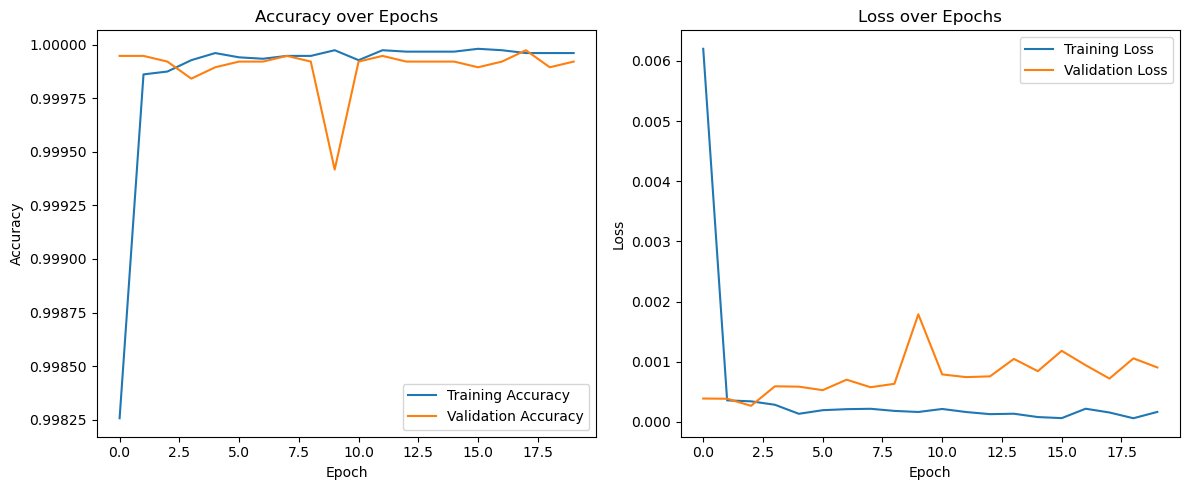

In [39]:
plt.figure(figsize=(12, 5))

# Plot accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

---
## 📈 Step 10 — ANN Evaluation & Confusion Matrix


**What we do here:**
- Evaluate ANN on test set: loss and accuracy
- Generate confusion matrix (True Positive / False Positive / False Negative / True Negative)
- All 3 models comparison table: RF vs DT vs ANN



In [40]:
# Step 1: Get probability predictions from the ANN
y_pred_ann_prob = model.predict(X_test_scaled)

# Step 2: Convert probabilities to 0/1 labels (threshold = 0.5)
y_pred_ann = (y_pred_ann_prob > 0.5).astype(int)

# Step 3: Print the 4 metrics
print("Accuracy:", accuracy_score(y_test, y_pred_ann))
print("Precision:", precision_score(y_test, y_pred_ann))
print("Recall:", recall_score(y_test, y_pred_ann))
print("F1 Score:", f1_score(y_test, y_pred_ann))

1474/1474 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step
Accuracy: 0.9999363854195381
Precision: 0.9998887776665555
Recall: 1.0
F1 Score: 0.9999443857405038


In [41]:
# Create a comparison table of all 3 models
comparison_all = pd.DataFrame({
    'Model': ['Random Forest', 'Decision Tree', 'ANN (Deep Learning)'],
    'Accuracy': [
        accuracy_score(y_test, y_pred), 
        accuracy_score(y_test, y_pred_dt), 
        accuracy_score(y_test, y_pred_ann)
    ],
    'Precision': [
        precision_score(y_test, y_pred), 
        precision_score(y_test, y_pred_dt), 
        precision_score(y_test, y_pred_ann)
    ],
    'Recall': [
        recall_score(y_test, y_pred), 
        recall_score(y_test, y_pred_dt), 
        recall_score(y_test, y_pred_ann)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred), 
        f1_score(y_test, y_pred_dt), 
        f1_score(y_test, y_pred_ann)
    ]
})

print(comparison_all)

                 Model  Accuracy  Precision  Recall  F1 Score
0        Random Forest  1.000000   1.000000     1.0  1.000000
1        Decision Tree  1.000000   1.000000     1.0  1.000000
2  ANN (Deep Learning)  0.999936   0.999889     1.0  0.999944


In [42]:
cm = confusion_matrix(y_test, y_pred_ann)
print(cm)

[[20186     3]
 [    0 26970]]


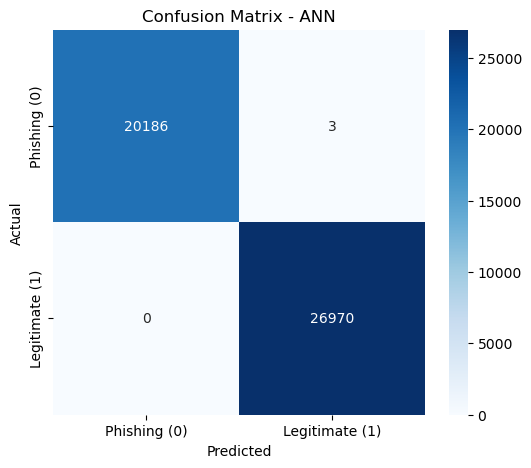

In [43]:
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Phishing (0)', 'Legitimate (1)'],
            yticklabels=['Phishing (0)', 'Legitimate (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - ANN')
plt.show()

---
## 💾 Step 11 — Save Models


**What we do here:**
- Save the trained Random Forest model → `rf_model.joblib`
- Save the trained Decision Tree model → `dt_model.joblib`
- Save the trained ANN model → `ann_model.keras`
- Save the fitted StandardScaler → `scaler.joblib`
- These files are loaded by `app.py` to make real-time predictions



In [44]:
import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, 'rf_model.joblib')

# Save the trained Decision Tree model
joblib.dump(dt_model, 'dt_model.joblib')

# Save the ANN model (TensorFlow format)
model.save('ann_model.keras')

# Save the scaler (needed to transform new data the same way)
joblib.dump(scaler, 'scaler.joblib')

print("All models and scaler saved!")
print("  rf_model.joblib  — Random Forest")
print("  dt_model.joblib  — Decision Tree")
print("  ann_model.keras  — ANN (TensorFlow)")
print("  scaler.joblib    — StandardScaler")

All models and scaler saved!
  rf_model.joblib  — Random Forest
  dt_model.joblib  — Decision Tree
  ann_model.keras  — ANN (TensorFlow)
  scaler.joblib    — StandardScaler


---
## ✅ Step 12 — Conclusion


**Summary of Results:**

| Model | Accuracy | Notes |
|-------|----------|-------|
| Random Forest | 100% | Best overall; 100 trees; most important feature: URLSimilarityIndex (19%) |
| Decision Tree | 100% | Simpler model; single tree; same accuracy on this dataset |
| ANN | 99.99% | Deep learning; 3 layers; 20 epochs |

**Key Findings:**
- All three models achieve near-perfect accuracy on the 235,795-row dataset
- `URLSimilarityIndex` is the single most important feature (19% contribution in RF)
- Even without `URLSimilarityIndex`, the model still performs well — the remaining 50 features carry enough signal
- Feature scaling (`StandardScaler`) is critical: the saved scaler must receive features in the exact same order used during training (`TLD_encoded` last)

**What we built:**
1. A full ML pipeline: data cleaning → encoding → scaling → training → evaluation → saving
2. A `extract_features(url)` function that extracts all 51 features from any URL in real time
3. A Streamlit web app (`app.py`) that uses the saved models to predict phishing URLs live



---
## ⚙️ Step 14 — Feature Extraction Function (`extract_features`)


**What we do here:**
- Define a single clean function `extract_features(url)` that extracts all 51 features
- **Part 1:** URL-based features (no network needed — works offline)
- **Part 2:** Web content features (fetches the page with `requests`, parses HTML with `BeautifulSoup`)
- Returns a dict with features in the correct order for the scaler

**⚠️ Feature order matters:** `TLD_encoded` must always be the last key in the returned dictionary.



In [45]:
def extract_features(url):
    from urllib.parse import urlparse
    import re
    import requests
    from bs4 import BeautifulSoup
    import math

    # --- Part 1: URL-based features ---
    parsed = urlparse(url)
    url_length = len(url)
    is_https = 1 if url.startswith('https') else 0
    no_of_digits = sum(c.isdigit() for c in url)
    domain_parts = parsed.netloc.split('.')
    no_of_subdomain = max(len(domain_parts) - 2, 0)
    is_domain_ip = 1 if re.match(r'^\d{1,3}(\.\d{1,3}){3}$', parsed.netloc) else 0
    tld = domain_parts[-1] if domain_parts else ''
    tld_length = len(tld)
    no_of_letters = sum(c.isalpha() for c in url)
    letter_ratio = no_of_letters / url_length if url_length > 0 else 0
    digit_ratio = no_of_digits / url_length if url_length > 0 else 0
    no_of_equals = url.count('=')
    no_of_qmark = url.count('?')
    no_of_ampersand = url.count('&')
    no_of_other_special = sum(1 for c in url if c in ['@','!','#','$','%','^','*'])
    special_char_ratio = no_of_other_special / url_length if url_length > 0 else 0
    domain_length = len(parsed.netloc)

    # --- Part 2: Fetch the webpage ---
    try:
        headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
        response = requests.get(url, headers=headers, timeout=10)
        soup = BeautifulSoup(response.text, 'html.parser')
        page_text = response.text.lower()

        # --- Part 3: Content-based features ---
        no_of_image = len(soup.find_all('img'))
        no_of_js = len(soup.find_all('script'))
        no_of_css = len(soup.find_all('link', rel='stylesheet'))
        line_of_code = len(response.text.split('\n'))
        largest_line = max((len(l) for l in response.text.split('\n')), default=0)
        no_of_self_ref = len([a for a in soup.find_all('a', href=True)
                               if parsed.netloc in a['href']])
        no_of_empty_ref = len([a for a in soup.find_all('a', href=True)
                                if a['href'] in ['#', '', '/']])
        no_of_external_ref = len([a for a in soup.find_all('a', href=True)
                                   if a['href'].startswith('http')
                                   and parsed.netloc not in a['href']])

        # --- Part 4: Judgment-based features ---
        has_title = 1 if soup.find('title') else 0
        has_favicon = 1 if soup.find('link', rel=lambda r: r and 'icon' in r) else 0
        has_description = 1 if soup.find('meta', attrs={'name': 'description'}) else 0
        is_responsive = 1 if soup.find('meta', attrs={'name': 'viewport'}) else 0
        robots = 1 if soup.find('meta', attrs={'name': 'robots'}) else 0
        has_submit = 1 if soup.find('input', type='submit') or soup.find('button') else 0
        has_hidden = 1 if soup.find('input', type='hidden') else 0
        has_password = 1 if soup.find('input', type='password') else 0
        no_of_iframe = len(soup.find_all('iframe'))
        no_of_popup = page_text.count('window.open')
        has_ext_form = 1 if any(parsed.netloc not in f.get('action', '')
                                 for f in soup.find_all('form', action=True)) else 0
        social_keywords = ['facebook.com', 'twitter.com', 'instagram.com',
                           'linkedin.com', 'youtube.com']
        has_social = 1 if any(k in page_text for k in social_keywords) else 0
        has_copyright = 1 if '©' in page_text or 'copyright' in page_text else 0
        bank = 1 if any(k in page_text for k in ['bank', 'banking']) else 0
        pay = 1 if any(k in page_text for k in ['paypal', 'payment', 'pay now']) else 0
        crypto = 1 if any(k in page_text for k in ['bitcoin', 'crypto', 'ethereum']) else 0

        # URL Similarity Index: default 50 (neutral) since we cannot compute it exactly
        url_similarity = 50

        # TLD encoded: use label encoder if available, else 0
        try:
            le = joblib.load('le.joblib')
            tld_encoded = int(le.transform([tld])[0]) if tld in le.classes_ else 0
        except:
            tld_encoded = 0

        # Char continuation rate and URL char prob: simplified estimates
        char_continuation = len(max(re.findall(r'[a-z]+', url), key=len, default='')) / url_length if url_length > 0 else 0
        url_char_prob = no_of_letters / url_length if url_length > 0 else 0
        obfuscation = 1 if '%' in url else 0
        no_of_obfuscated = url.count('%')
        obfuscation_ratio = no_of_obfuscated / url_length if url_length > 0 else 0

    except Exception as e:
        print(f"Could not fetch {url}: {e}")
        return None

    # --- Combine all 51 features ---
    features = {
        'URLLength': url_length,
        'DomainLength': domain_length,
        'IsDomainIP': is_domain_ip,
        'URLSimilarityIndex': url_similarity,
        'CharContinuationRate': char_continuation,
        'TLDLegitimateProb': 0.8 if tld in ['com','org','net','edu','gov'] else 0.3,
        'URLCharProb': url_char_prob,
        'TLDLength': tld_length,
        'NoOfSubDomain': no_of_subdomain,
        'HasObfuscation': obfuscation,
        'NoOfObfuscatedChar': no_of_obfuscated,
        'ObfuscationRatio': obfuscation_ratio,
        'NoOfLettersInURL': no_of_letters,
        'LetterRatioInURL': letter_ratio,
        'NoOfDegitsInURL': no_of_digits,
        'DegitRatioInURL': digit_ratio,
        'NoOfEqualsInURL': no_of_equals,
        'NoOfQMarkInURL': no_of_qmark,
        'NoOfAmpersandInURL': no_of_ampersand,
        'NoOfOtherSpecialCharsInURL': no_of_other_special,
        'SpacialCharRatioInURL': special_char_ratio,
        'IsHTTPS': is_https,
        'LineOfCode': line_of_code,
        'LargestLineLength': largest_line,
        'HasTitle': has_title,
        'DomainTitleMatchScore': 0,
        'URLTitleMatchScore': 0,
        'HasFavicon': has_favicon,
        'Robots': robots,
        'IsResponsive': is_responsive,
        'NoOfURLRedirect': 0,
        'NoOfSelfRedirect': 0,
        'HasDescription': has_description,
        'NoOfPopup': no_of_popup,
        'NoOfiFrame': no_of_iframe,
        'HasExternalFormSubmit': has_ext_form,
        'HasSocialNet': has_social,
        'HasSubmitButton': has_submit,
        'HasHiddenFields': has_hidden,
        'HasPasswordField': has_password,
        'Bank': bank,
        'Pay': pay,
        'Crypto': crypto,
        'HasCopyrightInfo': has_copyright,
        'NoOfImage': no_of_image,
        'NoOfCSS': no_of_css,
        'NoOfJS': no_of_js,
        'NoOfSelfRef': no_of_self_ref,
        'NoOfEmptyRef': no_of_empty_ref,
        'NoOfExternalRef': no_of_external_ref,
        'TLD_encoded': tld_encoded,
    }

    return features

# Test the function
result = extract_features("https://www.wikipedia.org")
print(result)

{'URLLength': 25, 'DomainLength': 17, 'IsDomainIP': 0, 'URLSimilarityIndex': 50, 'CharContinuationRate': 0.36, 'TLDLegitimateProb': 0.8, 'URLCharProb': 0.8, 'TLDLength': 3, 'NoOfSubDomain': 1, 'HasObfuscation': 0, 'NoOfObfuscatedChar': 0, 'ObfuscationRatio': 0.0, 'NoOfLettersInURL': 20, 'LetterRatioInURL': 0.8, 'NoOfDegitsInURL': 0, 'DegitRatioInURL': 0.0, 'NoOfEqualsInURL': 0, 'NoOfQMarkInURL': 0, 'NoOfAmpersandInURL': 0, 'NoOfOtherSpecialCharsInURL': 0, 'SpacialCharRatioInURL': 0.0, 'IsHTTPS': 1, 'LineOfCode': 1016, 'LargestLineLength': 55935, 'HasTitle': 1, 'DomainTitleMatchScore': 0, 'URLTitleMatchScore': 0, 'HasFavicon': 1, 'Robots': 0, 'IsResponsive': 1, 'NoOfURLRedirect': 0, 'NoOfSelfRedirect': 0, 'HasDescription': 1, 'NoOfPopup': 0, 'NoOfiFrame': 0, 'HasExternalFormSubmit': 0, 'HasSocialNet': 0, 'HasSubmitButton': 1, 'HasHiddenFields': 1, 'HasPasswordField': 0, 'Bank': 1, 'Pay': 0, 'Crypto': 0, 'HasCopyrightInfo': 1, 'NoOfImage': 7, 'NoOfCSS': 0, 'NoOfJS': 4, 'NoOfSelfRef': 0, 

In [46]:
df_clean.to_csv("project_cleaned.csv", index=False)